# Del dato al grafo: desarrollo paso a paso

**Teoría de grafos y algoritmo de Louvain para la detección de comunidades estructurales.
Aplicación al abandono escolar por provincia en Ecuador**

Jhon Ronald Barros Naranjo, MSc. y Dimas Geovanny Vera Pisco · Universidad Técnica de Manabí
IX Congreso Internacional de Ciencias Básicas (CCIUTM 2026)

Este cuaderno reconstruye la ponencia de principio a fin con los datos oficiales. Cada
sección corresponde a una ecuación y a una diapositiva. Lea el texto, ejecute cada celda
(`Shift + Enter`) y compare con lo que se mostró en la ponencia.

| Sección | Ecuación | Diapositiva |
|---|---|---|
| 1. Los datos | | 4 |
| 2. Tasa por provincia y grado | (0) | 4 |
| 3. Estandarización | (1) | 6 |
| 4. Similitud y umbral | (2) y (3) | 7 |
| 5. Modularidad y Louvain | (4) | 8 y 9 |
| 6. Validez frente a las Zonas | | 10 |
| 7. Robustez al umbral | | 11 |
| 8. Segunda capa | | 12 |
| 9. Ejercicios | | |

## 0. Preparación

Si usa **Google Colab**, la primera celda descarga el repositorio e instala lo necesario.
En su computadora basta con `pip install -r requirements.txt` desde la raíz del repositorio
y abrir este cuaderno desde la carpeta `tutorial/`.

In [1]:
import os, sys, subprocess

if "google.colab" in sys.modules and not os.path.exists("replicacion-cciutm2026"):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/jbarrosn/replicacion-cciutm2026"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "igraph", "geopandas"], check=True)
    os.chdir("replicacion-cciutm2026/tutorial")

RAIZ = os.path.abspath("..")
sys.path.insert(0, os.path.join(RAIZ, "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from grafo_abandono.configuracion import cargar_config
from grafo_abandono.lectura import leer_amie, leer_vab
from grafo_abandono.provincias import zona_modal
from grafo_abandono.tasas import columnas

cfg = cargar_config(os.path.join(RAIZ, "config.yaml"))
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Listo")

Listo


## 1. Los datos

La fuente es el **AMIE 2024-2025 (Fin)** del Ministerio de Educación, Deporte y Cultura: una
fila por institución educativa, con la matrícula y el abandono de cada grado separados por
sexo. Se conservan las 24 provincias (se excluyen 8 registros de "Zona No Delimitada").

In [2]:
amie = leer_amie(cfg)
print(f"Instituciones: {len(amie):,}   Columnas: {amie.shape[1]}   Provincias: {amie['provincia'].nunique()}")

# Una mirada a la tabla original: cinco instituciones de Manabí, solo 1.º de Bachillerato
g = "1erAñoBachillerato"
cols = ["AMIE", "Provincia", "Cantón"] + columnas(cfg, g, "matricula") + columnas(cfg, g, "abandono")
con_bgu = amie[columnas(cfg, g, "matricula")].sum(axis=1) > 0
amie.loc[(amie["provincia"] == "Manabí") & con_bgu, cols].head()

Instituciones: 16,186   Columnas: 177   Provincias: 24


,AMIE,Provincia,Cantón,Estudiantes1erAñoBachilleratoMujeres,Estudiantes1erAñoBachilleratoHombres,EstudiantesMujeresAbandono1erAñoBachillerato,EstudiantesHombresAbandono1erAñoBachillerato
648,13H01158,MANABI,CHONE,1,0,0,0
5615,13H01058,MANABI,CHONE,3,1,0,0
6131,13H04718,MANABI,SANTA ANA,1,3,0,0
6357,13H01689,MANABI,FLAVIO ALFARO,3,3,1,1
6542,13H03055,MANABI,PICHINCHA,5,2,0,0


**Para pensar.** Cada institución aporta 60 números de interés (15 grados × 2 sexos ×
matrícula y abandono). ¿Por qué no comparar directamente las 16 186 instituciones? Porque la
pregunta es territorial: queremos saber cómo se parecen las **provincias** entre sí.

## 2. Ecuación (0): tasa de abandono por provincia y grado

Sumamos mujeres y hombres de todas las instituciones de la provincia $u$ en el grado $j$:

$$
t_{u,j} \;=\; \frac{A_{u,j}}{M_{u,j}} \times 100,
\qquad u = 1,\dots,24,\quad j = 1,\dots,15
$$

donde $A_{u,j}$ son los estudiantes que abandonan y $M_{u,j}$ los matriculados. El resultado
es una matriz $T$ de $24 \times 15$: **cada fila es el perfil de una provincia**.

In [3]:
from grafo_abandono.tasas import matriz_tasas, tasa_total

T, A, M = matriz_tasas(amie, cfg)
print("Dimensión de T:", T.shape)
T.round(2).head(6)

Dimensión de T: (24, 15)


,Inicial 1,Inicial 2,1.º EGB,2.º EGB,3.º EGB,4.º EGB,5.º EGB,6.º EGB,7.º EGB,8.º EGB,9.º EGB,10.º EGB,1.º BGU,2.º BGU,3.º BGU
Azuay,1.70,0.84,0.86,0.91,0.90,0.80,0.73,0.74,0.59,1.14,1.43,1.33,3.15,2.25,1.05
Bolívar,1.36,0.76,0.80,1.08,0.69,0.54,0.57,0.37,0.55,2.33,2.22,2.84,4.96,4.23,3.87
Cañar,1.53,0.79,1.25,0.97,0.71,0.71,0.89,0.95,1.20,1.90,1.73,1.94,3.42,2.59,1.24
Carchi,0.93,0.70,0.59,0.63,1.22,0.69,0.82,0.48,0.68,3.01,1.92,1.11,3.19,1.49,0.26
Chimborazo,2.68,0.96,0.80,0.81,0.69,0.65,0.54,0.56,0.59,2.85,2.34,2.11,5.45,3.54,1.47
Cotopaxi,0.83,0.63,0.52,0.64,0.42,0.62,0.40,0.45,0.39,1.21,1.12,1.70,2.69,2.25,0.55


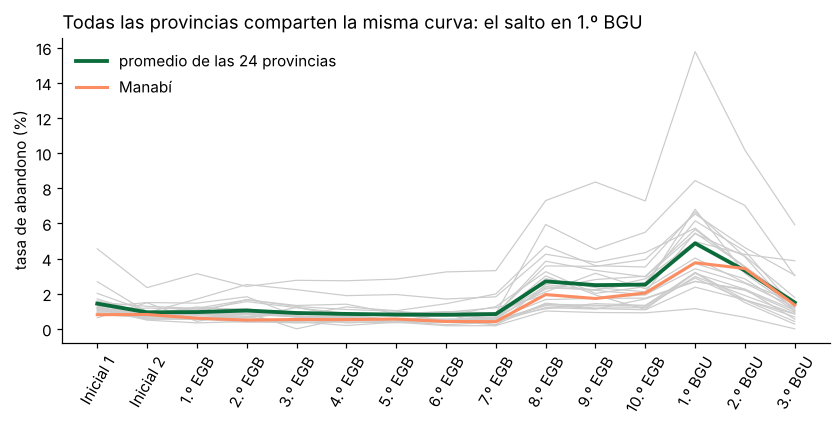

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for prov in T.index:
    ax.plot(T.columns, T.loc[prov], color="0.8", lw=0.8)
ax.plot(T.columns, T.mean(), color="#0B6B3A", lw=2.5, label="promedio de las 24 provincias")
ax.plot(T.columns, T.loc["Manabí"], color="#FC8D62", lw=2, label="Manabí")
ax.set_ylabel("tasa de abandono (%)"); ax.tick_params(axis="x", rotation=60)
ax.set_title("Todas las provincias comparten la misma curva: el salto en 1.º BGU", loc="left")
ax.legend(frameon=False); plt.show()

Todas las curvas suben en 8.º a 10.º de Básica y saltan en **1.º de Bachillerato**. Esa
forma común es real, pero es un problema para comparar provincias: si dos curvas suben y bajan
juntas, su correlación será alta aunque sus diferencias relativas sean distintas.

## 3. Ecuación (1): estandarización por grado

Para cada grado $j$ restamos la media y dividimos entre la desviación estándar de las 24
provincias:

$$
z_{u,j} \;=\; \frac{t_{u,j} - \mu_j}{\sigma_j},
\qquad
\mu_j = \frac{1}{24}\sum_{u} t_{u,j},
\qquad
\sigma_j = \sqrt{\frac{1}{23}\sum_{u}\left(t_{u,j}-\mu_j\right)^2}
$$

Así cada grado queda con media 0 y varianza 1, y $z_{u,j}$ mide **cuánto se aparta la
provincia $u$ del promedio nacional en ese grado**. La curva compartida desaparece.

In [5]:
from grafo_abandono.metodo import estandarizar, similitud, pares

Z = estandarizar(T)
print("Media por grado (≈ 0):", Z.mean().abs().max().round(10))
print("Desv. estándar por grado (= 1):", Z.std().round(6).unique())

sin_z, con_z = pares(similitud(T)), pares(similitud(Z))
print(f"\nSin (1): {np.sum(sin_z > 0)} de {len(sin_z)} pares con ρ > 0, mediana {np.median(sin_z):.2f}")
print(f"Con (1): {np.sum(con_z > 0)} de {len(con_z)} pares con ρ > 0, mediana {np.median(con_z):.2f}")

Media por grado (≈ 0): 0.0
Desv. estándar por grado (= 1): [1.]

Sin (1): 276 de 276 pares con ρ > 0, mediana 0.92
Con (1): 130 de 276 pares con ρ > 0, mediana -0.02


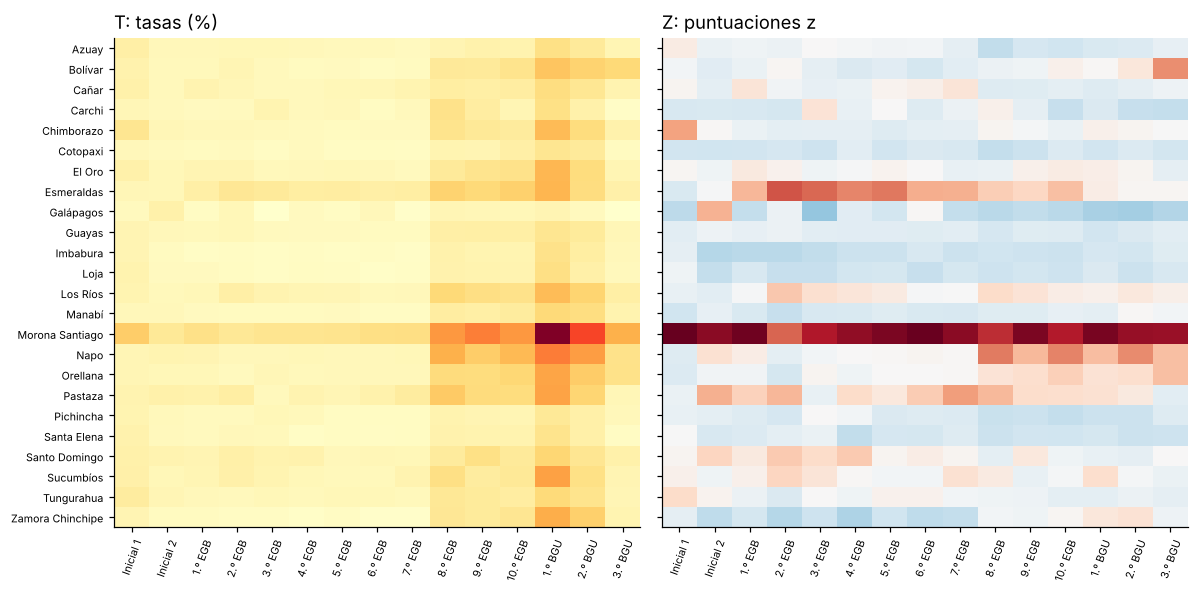

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
axs[0].imshow(T, aspect="auto", cmap="YlOrRd"); axs[0].set_title("T: tasas (%)", loc="left")
lim = np.abs(Z.values).max()
axs[1].imshow(Z, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim); axs[1].set_title("Z: puntuaciones z", loc="left")
for ax in axs:
    ax.set_xticks(range(15), T.columns, rotation=70, fontsize=7)
axs[0].set_yticks(range(24), T.index, fontsize=7)
plt.tight_layout(); plt.show()

A la izquierda domina la banda vertical de 1.º BGU (lo común). A la derecha esa banda
desaparece y aparecen **patrones por fila**: lo propio de cada provincia.

## 4. Ecuaciones (2) y (3): similitud y umbral

**Similitud.** Para cada par de provincias $u, v$ calculamos la correlación de Pearson entre
sus perfiles estandarizados:

$$
\rho(u,v) \;=\;
\frac{\sum_{j=1}^{15}\left(z_{u,j}-\bar z_u\right)\left(z_{v,j}-\bar z_v\right)}
{\sqrt{\sum_{j}\left(z_{u,j}-\bar z_u\right)^2}\;\sqrt{\sum_{j}\left(z_{v,j}-\bar z_v\right)^2}},
\qquad \rho \in [-1, 1]
$$

Hay $\binom{24}{2} = 276$ pares. Si los conectáramos todos tendríamos un grafo completo, sin
estructura.

**Umbral.** Conservamos solo el 25 % de pares más parecidos:

$$
A_{u,v} \;=\; \mathbf{1}\!\left[\rho(u,v) \ge q_{0.75}\right],
$$

donde $q_{0.75}$ es el percentil 75 de las 276 similitudes. Cada arista conservada pesa $\rho(u,v)$.

Umbral q_0.75 = 0.207   aristas que lo superan: 69


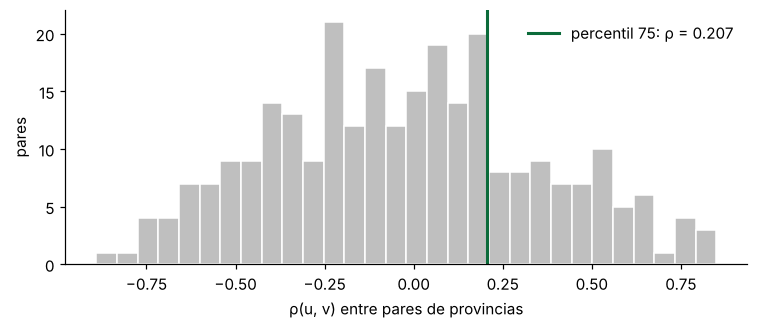

In [7]:
S = similitud(Z)
q = np.quantile(pares(S), 0.75)
print(f"Umbral q_0.75 = {q:.3f}   aristas que lo superan: {np.sum(pares(S) >= q)}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(pares(S), bins=30, color="0.75", edgecolor="white")
ax.axvline(q, color="#0B6B3A", lw=2, label=f"percentil 75: ρ = {q:.3f}")
ax.set_xlabel("ρ(u, v) entre pares de provincias"); ax.set_ylabel("pares"); ax.legend(frameon=False)
plt.show()

In [8]:
from grafo_abandono.metodo import construir_grafo

grafo = construir_grafo(S, 0.75, pesos="rho")
print(f"Nodos: {grafo.nodos}   Aristas: {grafo.aristas}   Densidad: {grafo.densidad:.3f}")
print("Provincias aisladas:", grafo.aisladas)

# Densidad = aristas / pares posibles entre los nodos que quedan
n = grafo.nodos
print(f"Comprobación: {grafo.aristas} / C({n}, 2) = {grafo.aristas / (n * (n - 1) / 2):.3f}")

Nodos: 23   Aristas: 69   Densidad: 0.273
Provincias aisladas: ['Cotopaxi']
Comprobación: 69 / C(23, 2) = 0.273


## 5. Ecuación (4): modularidad y Louvain

Una partición $c$ asigna cada nodo a una comunidad. Su **modularidad** compara el peso de las
aristas dentro de las comunidades con el que se esperaría por azar:

$$
Q \;=\; \frac{1}{2m}\sum_{u,v}\left[A_{uv} - \frac{k_u k_v}{2m}\right]\delta(c_u, c_v)
$$

- $A_{uv}$: peso de la arista (aquí, $\rho$; 0 si no hay arista)
- $k_u = \sum_v A_{uv}$: grado ponderado del nodo $u$
- $m = \tfrac{1}{2}\sum_{u,v} A_{uv}$: peso total de las aristas
- $\delta(c_u, c_v) = 1$ si $u$ y $v$ están en la misma comunidad

Buscar la partición de $Q$ máximo es NP-difícil. **Louvain** lo resuelve de forma voraz:
(i) mueve cada nodo a la comunidad vecina que más aumenta $Q$; (ii) colapsa cada comunidad
en un nodo y repite hasta que $Q$ deja de crecer.

In [9]:
from grafo_abandono.metodo import louvain

part = louvain(grafo, semilla=cfg["semilla"])
print(f"Comunidades: {part.k}   Q (igraph) = {part.Q:.3f}\n")
for c in sorted(part.comunidad.unique()):
    print(f"Comunidad {c}:", ", ".join(part.comunidad[part.comunidad == c].index))

Comunidades: 4   Q (igraph) = 0.446

Comunidad 1: Azuay, Cañar, Galápagos, Guayas, Pichincha, Santa Elena, Santo Domingo
Comunidad 2: Bolívar, El Oro, Manabí, Napo, Orellana, Zamora Chinchipe
Comunidad 3: Carchi, Esmeraldas, Los Ríos, Pastaza, Sucumbíos
Comunidad 4: Chimborazo, Imbabura, Loja, Morona Santiago, Tungurahua


**Verifiquemos $Q$ a mano** con la fórmula, usando la matriz de adyacencia ponderada:

In [10]:
nombres = grafo.g.vs["name"]
Aw = np.array(grafo.g.get_adjacency(attribute="weight").data, dtype=float)
k = Aw.sum(axis=1)                      # grados ponderados
dos_m = Aw.sum()                        # 2m
c = part.comunidad.reindex(nombres).to_numpy()
delta = (c[:, None] == c[None, :]).astype(float)

Q_manual = ((Aw - np.outer(k, k) / dos_m) * delta).sum() / dos_m
print(f"Q calculada con la fórmula (4): {Q_manual:.4f}")
print(f"Q reportada por igraph:         {part.Q:.4f}")

Q calculada con la fórmula (4): 0.4459
Q reportada por igraph:         0.4459


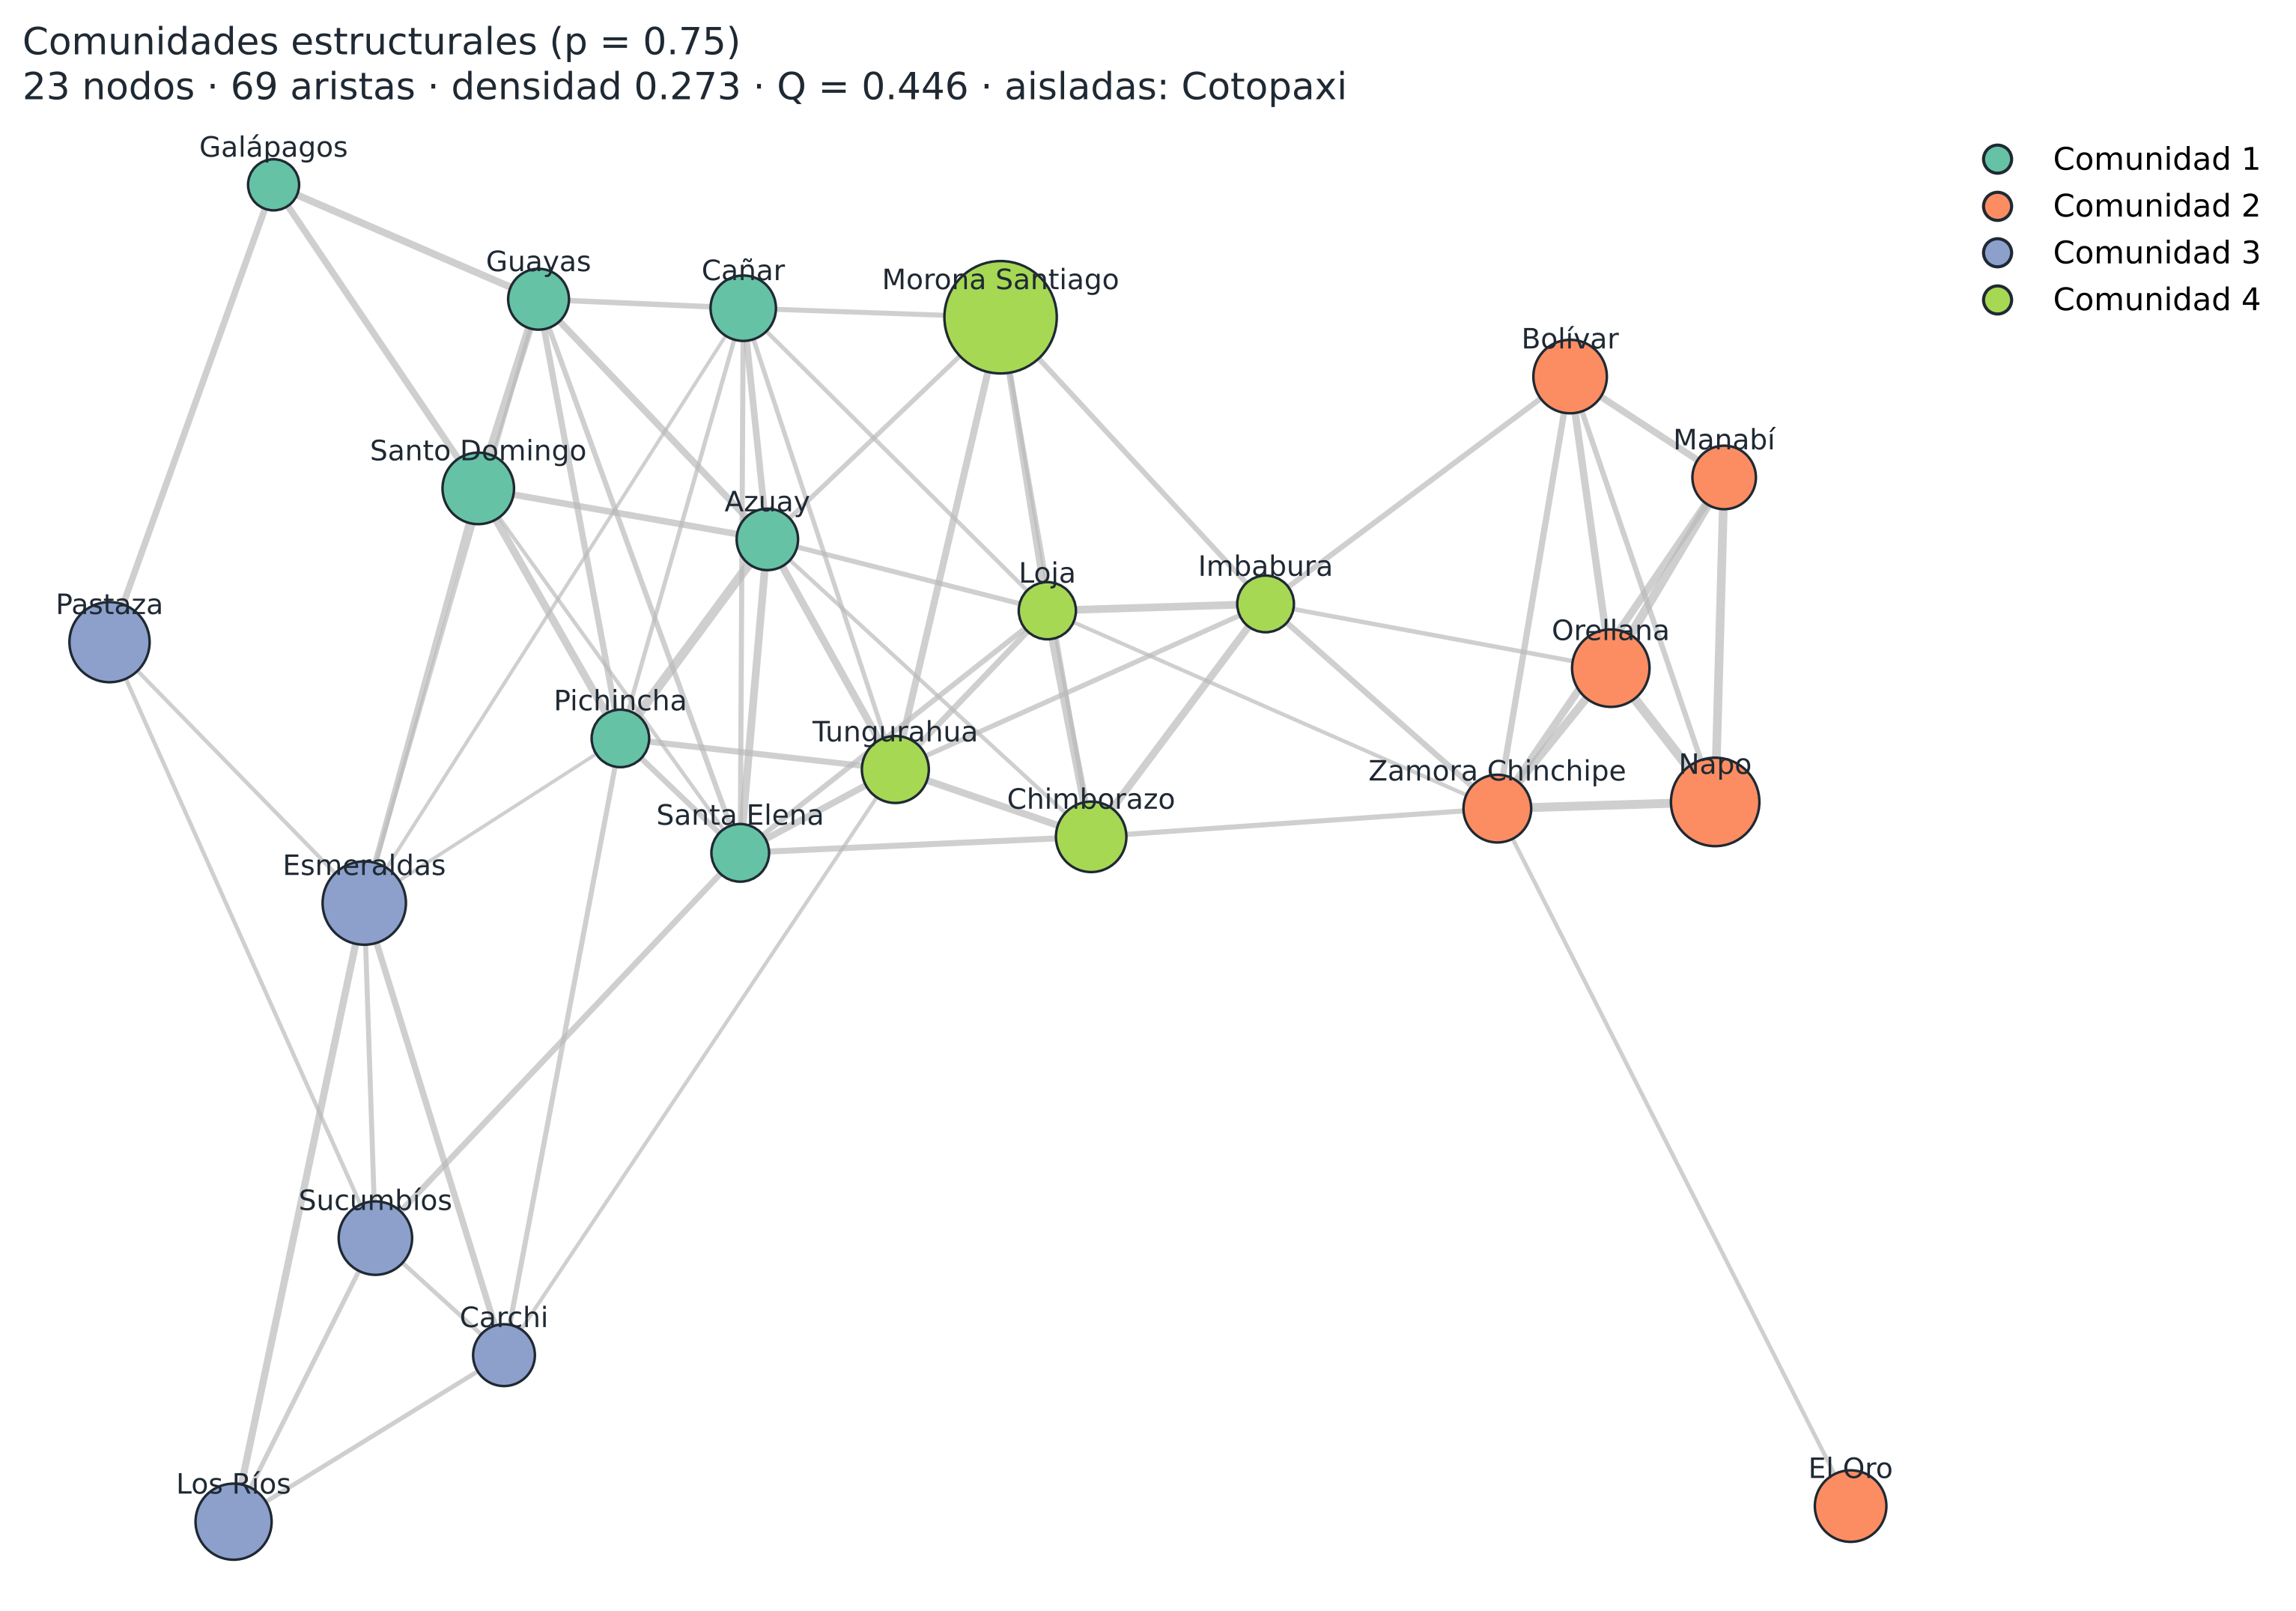

In [11]:
from grafo_abandono.figuras import dibujar_grafo
from IPython.display import Image

maestra = pd.DataFrame({"tasa_total_pct": tasa_total(A, M)})
os.makedirs("figuras_tutorial", exist_ok=True)
dibujar_grafo(grafo, part, maestra["tasa_total_pct"], "Comunidades estructurales (p = 0.75)",
              "figuras_tutorial/grafo.png", cfg["semilla"])
Image("figuras_tutorial/grafo.png", width=700)

## 6. Validez: ¿coinciden las comunidades con las Zonas de Planificación?

Si el grafo solo repitiera la organización administrativa, cada comunidad tendría provincias
de **una sola zona**. La zona de cada provincia es la que reúne más instituciones en el AMIE.

In [12]:
from grafo_abandono.validacion import cruce_zonas

zona = zona_modal(amie, cfg["amie_fin"]["columna_zona"])
cruce_zonas(part.comunidad, zona)

,comunidad,n_provincias,provincias,zonas,zonas_distintas
0,1,7,"Azuay, Cañar, Galápagos, Guayas, Pichincha, Sa...","4, 5, 6, 8, 9",5
1,2,6,"Bolívar, El Oro, Manabí, Napo, Orellana, Zamor...","2, 4, 5, 7",4
2,3,5,"Carchi, Esmeraldas, Los Ríos, Pastaza, Sucumbíos","1, 3, 5",3
3,4,5,"Chimborazo, Imbabura, Loja, Morona Santiago, T...","1, 3, 6, 7",4


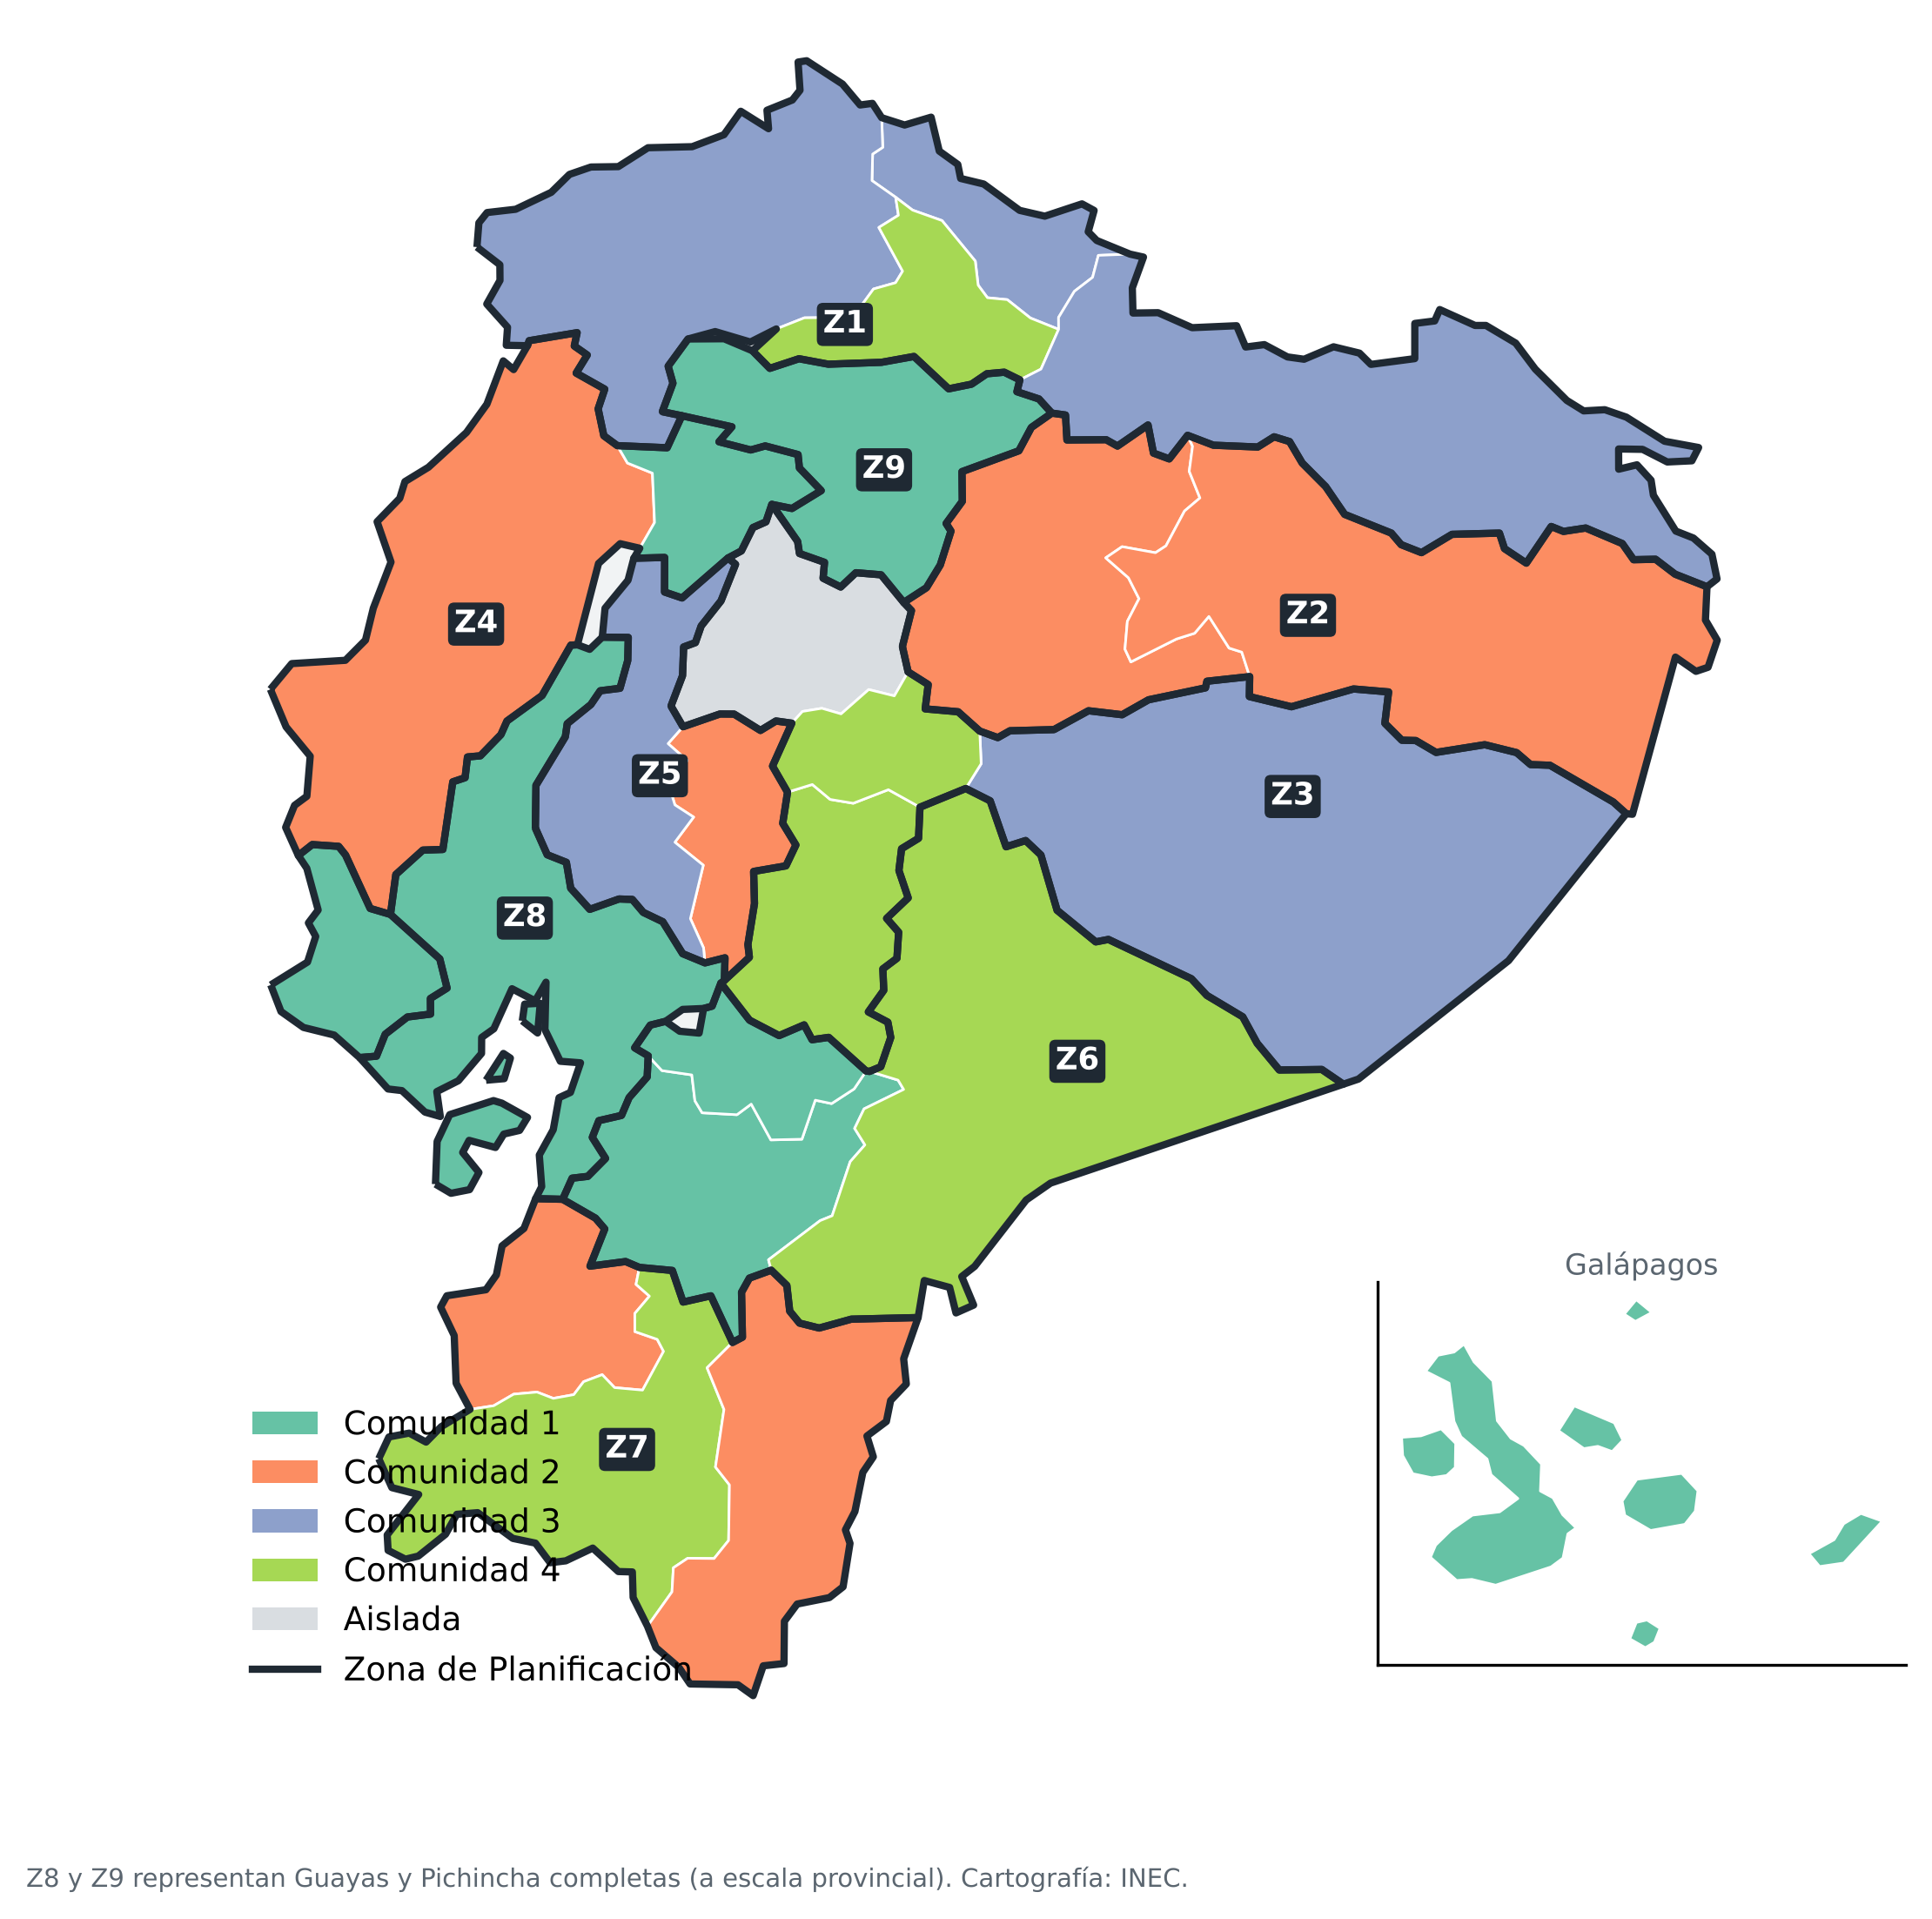

In [13]:
from grafo_abandono.figuras import mapa_comunidades

mapa_comunidades(cfg, part, zona, "figuras_tutorial/mapa_comunidades.png")
Image("figuras_tutorial/mapa_comunidades.png", width=520)

Cada comunidad cruza entre 3 y 5 zonas: el método encuentra una estructura que **no** estaba
dada de antemano por la zonificación. Ojo: esto es una diferencia estructural observada, no
una prueba de causalidad ni una evaluación de la gestión.

## 7. Robustez: ¿depende todo del percentil 75?

Repetimos las ecuaciones (3) y (4) con percentiles de 0.60 a 0.90. Con umbrales más altos
quedan menos aristas, pero más fuertes, y $Q$ sube.

In [14]:
from grafo_abandono.sensibilidad import tabla_sensibilidad

resumen, asign = tabla_sensibilidad(S, cfg["metodo"]["percentiles_sensibilidad"], cfg["semilla"])
resumen

,percentil,umbral_rho,nodos,aristas,densidad,comunidades,modularidad_Q,aisladas
0,0.60,0.059,24,111,0.402,3,0.372,
1,0.65,0.108,24,97,0.351,4,0.384,
2,0.70,0.166,24,83,0.301,4,0.409,
3,0.75,0.207,23,69,0.273,4,0.446,Cotopaxi
4,0.80,0.310,22,56,0.242,4,0.477,"Cotopaxi, El Oro"
5,0.85,0.395,22,42,0.182,4,0.553,"Cotopaxi, El Oro"
6,0.90,0.509,21,28,0.133,4,0.629,"Cotopaxi, El Oro, Sucumbíos"


In [15]:
# ¿Qué provincias cambian respecto de p = 0.75?
# Las etiquetas de comunidad son arbitrarias: cada comunidad de otro percentil se
# renombra como la comunidad de p = 0.75 con la que comparte más provincias.
ref = asign["p0.75"]
for col in asign.columns:
    s = asign[col]
    renombre = {c: ref[s == c].mode().iloc[0] if ref[s == c].notna().any() else c
                for c in s.dropna().unique()}
    cambian = [p for p in asign.index
               if pd.isna(s[p]) != pd.isna(ref[p]) or (pd.notna(s[p]) and renombre[s[p]] != ref[p])]
    print(f"{col}: {', '.join(cambian) or 'ninguna'}")

p0.60: Carchi, Cotopaxi, El Oro, Esmeraldas, Los Ríos, Pastaza, Sucumbíos
p0.65: Cotopaxi, El Oro, Pastaza
p0.70: Cotopaxi, Pastaza
p0.75: ninguna
p0.80: El Oro, Pastaza
p0.85: El Oro, Pastaza, Santa Elena, Sucumbíos
p0.90: El Oro, Pastaza, Santa Elena, Sucumbíos


Las provincias que aparecen en la lista son las **provincias frontera**: su perfil está a medio
camino entre dos comunidades o no se parece lo suficiente a ninguna. Merecen un análisis
cualitativo propio.

## 8. Segunda capa: abandono + recursos + contexto

Agregamos dos columnas al perfil: el **ratio estudiante/docente** (AMIE) y el **VAB per
cápita 2023** (Banco Central del Ecuador). La matriz pasa a $24 \times 17$; se estandariza y
se repite el método. Para comparar las dos matrices de similitud usamos la correlación entre
sus 276 pares.

In [16]:
from grafo_abandono.segunda_capa import ratio_estudiante_docente, matriz_ampliada, correlacion_matrices
from grafo_abandono.metodo import aplicar_metodo

maestra["ratio_estudiante_docente"] = ratio_estudiante_docente(amie, cfg)
maestra["vab_per_capita"] = leer_vab(cfg)
X = matriz_ampliada(T, maestra)

_, S2, grafo2, part2 = aplicar_metodo(X, 0.75, cfg["semilla"])
print(f"Correlación entre matrices de similitud (15 vs 17 variables): {correlacion_matrices(S, S2):.3f}")
print(f"Grafo con 17 variables: {grafo2.nodos} nodos, {part2.k} comunidades, Q = {part2.Q:.3f}, aisladas: {grafo2.aisladas}")
pd.crosstab(part.comunidad.reindex(T.index).fillna(0).astype(int).rename("solo abandono (0 = aislada)"),
            part2.comunidad.reindex(T.index).rename("abandono + contexto"))

Correlación entre matrices de similitud (15 vs 17 variables): 0.553
Grafo con 17 variables: 24 nodos, 4 comunidades, Q = 0.385, aisladas: []


abandono + contexto,1,2,3,4
solo abandono (0 = aislada),,,,
0,0,0,0,1
1,3,0,1,3
2,0,4,0,2
3,0,1,3,1
4,1,3,0,1


Una correlación de 0.55 es moderada: el vecindario de varias provincias cambia y
Cotopaxi vuelve a conectarse. **La desigualdad en resultados no es la misma que la desigualdad
en recursos.**

## 9. Ejercicios

1. **Sin estandarizar.** Construya el grafo con `similitud(T)` en lugar de `similitud(Z)`.
   ¿Cuántas aristas y comunidades obtiene? Explique el resultado con la gráfica de la sección 2.
2. **Pesos binarios.** Repita la sección 5 con `construir_grafo(S, 0.75, pesos="binario")`.
   ¿Cambian las comunidades? ¿Y $Q$?
3. **Otra medida de similitud.** Reemplace Pearson por Spearman
   (`Z.T.corr(method="spearman")`). ¿Qué provincias cambian de grupo?
4. **Semilla.** Ejecute Louvain con semillas 1 a 50 para $p = 0.70$. ¿Con qué frecuencia
   aparece cada partición? ¿Qué dice esto sobre las provincias frontera?
5. **Sin Galápagos.** Elimine Galápagos de $T$ antes de estandarizar. ¿Cambia el resto de la
   estructura? ¿Por qué Galápagos podría ser un caso especial?
6. **Por sexo.** Construya dos matrices, una con mujeres y otra con hombres
   (use `cfg["amie_fin"]["sexos"] = ["Mujeres"]`). ¿Las comunidades son las mismas?
7. **Verificación de Q.** Calcule a mano la modularidad de la partición por Zonas de
   Planificación sobre el mismo grafo. ¿Es mayor o menor que la de Louvain? Interprete.

---
*Datos: MINEDEC, Registros Administrativos AMIE 2024-2025 (Fin); Banco Central del Ecuador,
Cuentas Regionales; cartografía INEC.*